::: {.sb-lesson-links}
[Exercises →](../exercises/build-a-decision-tree.ipynb)
[Quiz →](../quiz/quiz.qmd)
[All files of this section (zip)](../../files/05-trees-and-forests.zip)
:::

::: {.sb-downloads}
[Download this notebook](../downloads/lesson-decision-trees.ipynb){download="lesson-decision-trees.ipynb"}  
Data: [customers.csv](../downloads/data/customers.csv){download="customers.csv"}

Put the data files in a folder named `data` next to the notebook.
:::

## What will you learn in this course? 🧐🧐

This course is very practical. The goal is to help you understand the theoretical principles of decision trees. A decision tree builds a sequence of binary rules to classify observations or to make regression predictions.

You will also learn the principle of bagging, which we will illustrate by moving from Decision Tree models to Random Forest models.

* Decision Tree (regression and classification)
* Building a decision tree
     * General principle
     * Division criterion
     * Admissibility
     * Heterogeneity
         * $Y$ quantitative
         * $Y$ qualitative
     * Stopping criterion
* Fight overfitting
* General Remarks

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree
import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"

## Decision Tree (regression and classification) 🌳🌳

Decision Trees belong to the family of recursive partitioning methods, better known by the acronym CART (_Classification And Regression Trees_). We speak of regression when the target variable is quantitative, and of classification when the target variable is qualitative (categorical). We start with Regression Trees, used when the target variable is quantitative; classification comes in a second step. A big advantage of trees is that their graphical representation is easy to read. A tree is made of three types of elements:

* The root, which contains all the training data. At the root, all training data form one undifferentiated block.
* The nodes/branches. Starting from the root, these are the points where the data is split into two subgroups. Each split uses a criterion on one of the explanatory variables, chosen to give the best possible prediction performance.
* The leaves, which are the terminal nodes of the tree. Each leaf carries a predicted value when $Y$ is quantitative, or a predicted class when $Y$ is qualitative.



::: {.callout-tip title="Intuition"}
A decision tree plays the game of "twenty questions" with your data. Each node asks one yes/no question about one variable ("is the age above 50?"), and each answer sends the observation down one branch. When there are no more questions to ask, the leaf you land in gives the answer: the average value, or the most frequent class, of the training observations that ended up in the same leaf.
:::



So, starting from the root, we define a first node that splits the dataset according to a performance criterion, which depends on one explanatory variable and on the target variable. For each of the two branches created, we repeat the same procedure, and so on. The tree is built step by step, node by node, which splits the training data into smaller and smaller subgroups, each with its own prediction. A stopping criterion tells us when to stop creating new nodes; the final nodes are the leaves, also called terminal nodes.


![decision_tree](../img/decision_tree.svg)

This is an example of a decision tree: the root is at the top, the first division branches out from the root, and the sequence of branches leads down to the leaves. Decision trees are very clear and visual, which makes them easy to interpret, as long as they stay reasonably small.

#### See it with data 🔬: a first tree

Let's grow a real tree. The file `customers.csv` describes 400 customers: their age, their salary, and whether they purchased a product (`Yes` / `No`). We ask for a tree with only two levels of questions (`max_depth=2`), so that it fits on the screen.

391 customers, training accuracy: 0.841


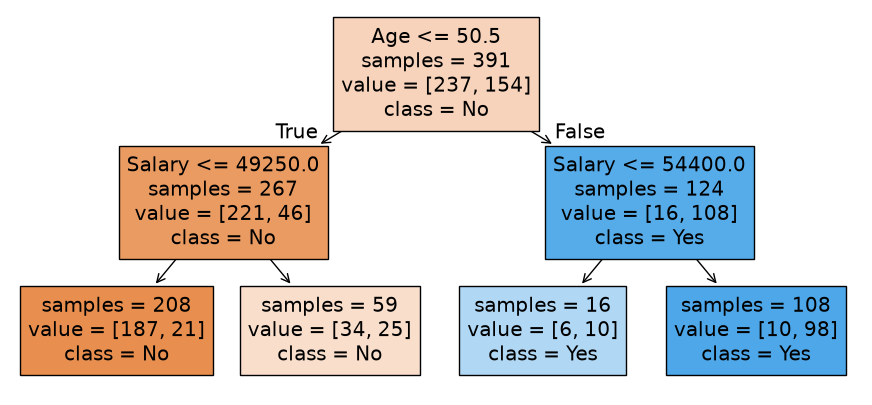

In [ ]:
customers = pd.read_csv("../data/customers.csv").dropna()   # 9 customers have no age
X = customers[["Age", "Salary"]]
y = customers["Purchased"]

tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y)
print(f"{len(customers)} customers, training accuracy: {tree.score(X, y):.3f}")

fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(tree, feature_names=["Age", "Salary"], class_names=list(tree.classes_),
          filled=True, impurity=False, ax=ax)
plt.show()

**What this shows:** the root (top box) holds all 391 customers. The first question is `Age <= 50.5`, then each branch asks one question about the salary. The 4 boxes at the bottom are the leaves. Their `value` line counts the customers of each class (`[No, Yes]`): the leftmost leaf holds 187 "No" and 21 "Yes", so it predicts No with confidence; its neighbour holds 34 "No" and 25 "Yes", and also predicts No, but it is much less sure. With only two questions, the tree already classifies 84.1% of the customers correctly.

## Building a decision tree 🛠🛠
### General principle

The decision tree construction algorithm works as follows (in pseudo code):

* Initialization: all the training data is assigned to the root. The root is the first node.
* For each node, we try to make a division:
    * We select an explanatory variable $X$ and define a cutoff criterion: a threshold if $X$ is quantitative, or a split into groups of modalities if $X$ is qualitative. In theory, every possible division of every explanatory variable is tested, and the algorithm selects the one that minimizes an error measure (we will look at it in detail later in the lesson). (Note that in scikit-learn only quantitative variables may be used, so the cutoff is always a threshold.)
    * The node is marked as terminal if no admissible division can be found (we will explain this in detail later in the lesson).
* The construction stops when all nodes are terminal. A predicted value or class is then assigned to each terminal node; we will see how below.

To complete this algorithm, we need three things:

1. A criterion for selecting the best division.
2. A set of rules to decide whether a division is admissible, and therefore when to create terminal nodes.
3. A method for assigning a value or class to each terminal node, or leaf.

### Division criterion

#### Admissibility

A division is **admissible** if both resulting child nodes are non-empty (i.e. at least one observation belongs to each child node). For a parent node containing $M$ observations, there are at most $M - 1$ possible divisions if the variable selected for the division is quantitative or qualitative ordinal, and at most $2^{M-1}-1$ admissible divisions if the selected variable is nominal. However, as mentioned above, scikit-learn only accepts quantitative variables, so all qualitative variables have to be converted to a numerical format.

#### Heterogeneity
To select the best admissible division, we define a **heterogeneity** function, which has two properties:

* It equals zero when all observations in a node belong to the same modality of $Y$ (classification), or have the same value of $Y$ (regression).
* It is maximal when the values of $Y$ are uniformly distributed in the node.

We then look for the division that minimizes the sum of the heterogeneities of the child nodes. Below, we define one heterogeneity function for regression and another one for classification.

#### $Y$ quantitative



::: {.callout-tip title="Intuition"}
Think of each node as a box of flat prices. If the box mixes small studios and large lofts, its average price is a poor guess for any flat inside: the prices are spread out, the variance is high. A good split sorts the flats into two boxes where prices are close to each other, so that the mean of each box becomes a good prediction. The formula below measures exactly this spread.
:::



In the case of regression, the heterogeneity of node $k$ is written as follows:

$$
H_k=\frac{1}{Card(k)}\cdot\sum_{i\in{k}}(y_i-\underline{y_k})^2
$$

$Card(k)$, also written $|k|$, is the number of elements in node $k$, and $\underline{y_k}$ is the mean of $Y$ over the observations of node $k$. In other words, $H_k$ is the variance of $Y$ in node $k$.
The division retained is the one for which $\frac{Card(k_G)}{Card(k)}H_{k_G}+\frac{Card(k_D)}{Card(k)}H_{k_D}$, the sum of the heterogeneities of the left branch and the right branch weighted by their sizes, is minimal.
Let's stop for a moment and think about this criterion. We are looking for the division that minimizes the sum of the variances of $Y$ in the left and right branches. The lower the variance of $Y$ in each branch, the more similar the observations within each branch are in terms of the target variable. If a model can put observations with similar values of $Y$ in the same branch, there is a good chance that it will be a good predictor!

#### See it with data 🔬: the variance criterion, by hand

Ten flats, with their surface (m²) and their price (k€). We want the best first question of the form "surface ≤ threshold?". With 10 different surfaces, there are 10 − 1 = 9 admissible divisions (one threshold between each pair of neighbours, as said in the Admissibility section). For each one, we compute the weighted variance of the two children, then we ask scikit-learn which split it picks.

In [ ]:
flats = pd.DataFrame({
    "surface": [30, 35, 42, 50, 55, 63, 70, 80, 90, 100],
    "price":   [120, 135, 128, 150, 160, 240, 255, 250, 270, 290],
})

def weighted_variance(left, right):
    n = len(left) + len(right)
    return len(left) / n * left.var(ddof=0) + len(right) / n * right.var(ddof=0)

surfaces = flats["surface"].to_numpy()
thresholds = (surfaces[:-1] + surfaces[1:]) / 2          # the 9 admissible cuts
scores = [weighted_variance(flats.price[flats.surface <= t], flats.price[flats.surface > t]) for t in thresholds]
print(f"Variance of the price at the root: {flats.price.var(ddof=0):.0f}")
pd.DataFrame({"threshold": thresholds, "weighted variance of the children": np.round(scores)})

Variance of the price at the root: 4003


,threshold,weighted variance of the children
0,32.5,3296.0
1,38.5,2697.0
2,46.0,1773.0
3,52.5,1051.0
4,59.0,258.0
5,66.5,1060.0
6,75.0,1891.0
7,85.0,2395.0
8,95.0,3099.0


In [ ]:
stump = DecisionTreeRegressor(max_depth=1).fit(flats[["surface"]], flats["price"])
print(export_text(stump, feature_names=["surface"]))

|--- surface <= 59.00
|   |--- value: [138.60]
|--- surface >  59.00
|   |--- value: [261.00]



**What this shows:** the price varies a lot at the root (variance 4003). Among the 9 admissible thresholds, "surface ≤ 59" gives by far the smallest weighted variance (258): it separates the five small, cheap flats from the five large, expensive ones. Scikit-learn tests the same 9 cuts and picks the same threshold, 59.0. Each leaf then predicts the mean price of its flats: 138.6 k€ on the left, 261.0 k€ on the right.

#### $Y$ qualitative



::: {.callout-tip title="Intuition"}
Gini impurity answers a simple question: if I pick one observation of the node at random and give it a label drawn at random with the proportions of the node, how often am I wrong? In a pure node (a single class) I am never wrong, so the impurity is 0. In a node with two classes in a 50/50 mix I am wrong half of the time: 0.5, the maximum for two classes.
:::



Let $Y$ be a qualitative variable with $m$ modalities, or categories, numbered from 1 to $m$. The heterogeneity function used most of the time is the GINI concentration (or Gini impurity):

$$
H_k=\sum_{i=1}^{m}p_{k}^{i}\cdot(1-p_{k}^{i})
$$

where $p_{k}^{i}$ is the proportion of class $i$ of $Y$ in node $k$. Let's analyze this formula. What happens when all observations in a branch belong to the same modality $y_j$ of $Y$? Then $p_{i}=0 \forall i \neq j$ and $1 - p_{j} = 0$, so the heterogeneity is 0. The formula reaches its maximum value when the values of $Y$ are uniformly distributed in the branch. Again, we try to minimize the sum of the heterogeneities of the branches. So the deeper we go into the tree, the more homogeneous the branches become: more and more observations in each node belong to the same class of $Y$.

#### See it with data 🔬: Gini impurity, by hand

Twelve customers of a small shop, with their age, their income (k€) and whether they bought something. We compare two candidate first questions, "age ≤ 36.5?" and "income ≤ 45?", by computing the weighted Gini impurity of the children, then we let scikit-learn choose.

In [ ]:
shop = pd.DataFrame({
    "age":    [22, 25, 28, 31, 35, 38, 42, 45, 49, 52, 58, 63],
    "income": [30, 52, 24, 61, 35, 28, 55, 40, 63, 33, 47, 58],
    "bought": ["no", "no", "no", "no", "no", "yes", "yes", "yes", "yes", "yes", "yes", "no"],
})

def gini(labels):
    p = labels.value_counts(normalize=True)       # proportion of each class
    return (p * (1 - p)).sum()

def split_gini(column, threshold):
    left = shop.bought[shop[column] <= threshold]
    right = shop.bought[shop[column] > threshold]
    return len(left) / len(shop) * gini(left) + len(right) / len(shop) * gini(right)

print(f"Gini at the root:   {gini(shop.bought):.3f}")
print(f"Split age <= 36.5:  {split_gini('age', 36.5):.3f}")
print(f"Split income <= 45: {split_gini('income', 45):.3f}")

Gini at the root:   0.500
Split age <= 36.5:  0.143
Split income <= 45: 0.500


In [ ]:
stump = DecisionTreeClassifier(max_depth=1).fit(shop[["age", "income"]], shop["bought"])
print(export_text(stump, feature_names=["age", "income"], show_weights=True))

|--- age <= 36.50
|   |--- weights: [5.00, 0.00] class: no
|--- age >  36.50
|   |--- weights: [1.00, 6.00] class: yes



**What this shows:** with 6 buyers and 6 non-buyers, the root is as mixed as it can be (Gini 0.500). Splitting on income does not help at all: both children are still 50/50, so the weighted Gini stays at 0.500. Splitting on age gives a pure left child (5 "no") and an almost pure right child (6 "yes", 1 "no"), and the weighted Gini drops to 0.143. Scikit-learn tries every threshold of both variables and also picks `age <= 36.50`.

### Stopping criterion

A given node is terminal in the following cases:

* when it is homogeneous, i.e. when all observations in the node have the same value or the same modality of $Y$;
* when there are no more admissible divisions;
* when the number of observations in the node is below a predefined value, usually a few units (in scikit-learn, this corresponds to the `min_samples_split` and `min_samples_leaf` arguments);
* when the tree reaches a certain depth (a certain number of successive divisions).

## Fight overfitting 👮👮

We saw earlier, with the LASSO and RIDGE models, that overfitting is a major risk in any supervised learning problem. For trees, the stopping criterion is key to limiting overfitting. With a very loose stopping criterion, the tree can grow to its fullest: terminal nodes will contain very few observations, and $Y$ will most probably be perfectly homogeneous in each of them. Such a tree will most likely get a near-perfect score on the training data, because it has fitted every single training observation.

![Train and test accuracy of a decision tree as its maximum depth grows](../img/tree_depth_overfitting.png)

In the figure above (a simulated dataset), the training accuracy keeps rising with the depth until it reaches 100%, while the test accuracy peaks at a small depth and then drops: the deeper tree is learning the noise of the training data.

 However, this only works well when the test observations are almost identical to the training examples. Any slight difference in the distribution of the variables in the test set can give very unpredictable results: sometimes good, but most likely incorrect. This is because we let the bias drop to zero and the variance go through the roof, which gives a model that will most likely generalize poorly to new data.

The goal is to find an intermediate tree that gives a better bias/variance trade-off for estimating $Y$. Unfortunately, the number of possible sub-trees is often very large, and checking the performance of every one of them would take a long time.

Instead, you can tune the stopping criteria with a grid search, to find the hyperparameters that maximize the prediction performance on data not used for training (cross-validation).

Reminder: the stopping criteria you can tune to reach a good bias/variance trade-off are:

* `min_samples_leaf`
* `min_samples_split`
* `max_depth`

#### See it with data 🔬: a regression tree is a staircase

200 noisy points around a sine wave. We fit three regression trees with `max_depth` 1, 3 and 10 and draw their predictions. We also measure the R² on 200 fresh points that the trees have never seen.

In [ ]:
rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 200)
y_noisy = np.sin(x) + rng.normal(0, 0.3, 200)
x_new = rng.uniform(0, 10, 200)                       # fresh points, never seen during training
y_new = np.sin(x_new) + rng.normal(0, 0.3, 200)
grid = np.linspace(0, 10, 500).reshape(-1, 1)

fig = go.Figure(go.Scatter(x=x, y=y_noisy, mode="markers", name="training data", marker=dict(color="#999999", size=5)))
for depth, color in zip([1, 3, 10], ["#3B47C4", "#2E7D4F", "#E4572E"]):
    reg = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(x.reshape(-1, 1), y_noisy)
    print(f"max_depth={depth:>2}: {reg.get_n_leaves():>3} leaves, train R² = {reg.score(x.reshape(-1, 1), y_noisy):.2f}, "
          f"test R² = {reg.score(x_new.reshape(-1, 1), y_new):.2f}")
    fig.add_trace(go.Scatter(x=grid.ravel(), y=reg.predict(grid), mode="lines", name=f"max_depth={depth}", line=dict(color=color)))
fig.update_layout(title="Predictions of regression trees of increasing depth", xaxis_title="x", yaxis_title="y")
fig.show()

max_depth= 1:   2 leaves, train R² = 0.16, test R² = 0.19
max_depth= 3:   8 leaves, train R² = 0.76, test R² = 0.67
max_depth=10: 151 leaves, train R² = 0.98, test R² = 0.62


**What this shows:** a regression tree predicts with flat steps, one step per leaf. With `max_depth=1` (2 leaves) the staircase is far too coarse: R² = 0.16 on the training data and 0.19 on new data (underfitting). With `max_depth=3` (8 leaves) the steps follow the wave: train R² = 0.76, test R² = 0.67. With `max_depth=10` the tree has 151 leaves for 200 points and chases the noise: almost perfect on the training data (R² = 0.98), but worse than depth 3 on new data (R² = 0.62). This is the overfitting described above.

#### See it with data 🔬: tuning `min_samples_leaf`

Back to the 391 customers. We keep 25% of them aside as a test set, then train trees that must keep at least `min_samples_leaf` customers in every leaf.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

rows = []
for leaf in [1, 2, 5, 10, 20, 50, 100]:
    model = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=0).fit(X_train, y_train)
    rows.append({"min_samples_leaf": leaf, "depth": model.get_depth(), "leaves": model.get_n_leaves(),
                 "train accuracy": round(model.score(X_train, y_train), 3),
                 "test accuracy": round(model.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,min_samples_leaf,depth,leaves,train accuracy,test accuracy
0,1,16,77,1.000,0.673
1,2,10,52,0.904,0.684
2,5,9,29,0.881,0.724
3,10,6,17,0.867,0.796
4,20,5,11,0.850,0.816
5,50,3,4,0.850,0.816
6,100,1,2,0.846,0.796


**What this shows:** with `min_samples_leaf=1` (no constraint) the tree grows 16 levels deep with 77 leaves, it is perfect on the training set (accuracy 1.000) but only reaches 0.673 on the test set. Asking for at least 20 customers per leaf gives a much smaller tree (11 leaves) that is less perfect on the training set (0.850) and much better on the test set (0.816). With 100 customers per leaf the tree has only 2 leaves and starts to underfit (test 0.796). In practice you choose this value by cross-validation, with a grid search.

## General remarks

* The algorithm tends to pay less attention to qualitative variables when they are converted into dummy variables. This is because the explanatory power of the variable is split over as many variables as there are modalities. A common strategy is to group rare modalities together, or modalities whose observations have a similar distribution of $Y$.

* Decision trees do not require special assumptions about the distributions of the variables (no normalization needed).

* Since a single variable is selected to create each node, the model performs an implicit variable selection. However, because only one variable is used for each split, less informative variables might not be included in the model, and only part of the information in the data will be used.

* The search for a division depends only on the order of the values of the quantitative explanatory variables, not on the values themselves. So the algorithm is robust to outliers and to skewed (asymmetric) distributions.

* Because of the hierarchical structure of the tree (divisions are made one by one), an error made at one division propagates to all the child nodes below it. Decision trees can therefore miss the global optimum, and so miss the true classification or regression function that links the explanatory variables to the target variable.

* In the case of regression, the tree gives a step function: all observations in the same leaf get the same estimated value of $Y$.

* If the true function is regular or smooth (for example a polynomial or a straight line), the decision tree model will not reproduce these properties.

#### See it with data 🔬: no scaling needed, only the order matters

Let's check two of these remarks. We train the same tree on the customers three times: on the raw features, after a `StandardScaler`, and on the logarithm of the features (a transformation that squeezes large values but keeps the order).

In [ ]:
raw = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
scaled = make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=3, random_state=0)).fit(X_train, y_train)
logged = DecisionTreeClassifier(max_depth=3, random_state=0).fit(np.log(X_train), y_train)

for name, data, labels in [("train", X_train, y_train), ("test", X_test, y_test)]:
    pred = raw.predict(data)
    print(f"{name}: accuracy {raw.score(data, labels):.3f} | same predictions after StandardScaler: "
          f"{(pred == scaled.predict(data)).mean():.0%}, after a log: {(pred == logged.predict(np.log(data))).mean():.0%}")
print("First question, raw:   ", export_text(raw, feature_names=["Age", "Salary"]).splitlines()[0])
print("First question, scaled:", export_text(scaled[-1], feature_names=["Age", "Salary"]).splitlines()[0])
print("First question, log:   ", export_text(logged, feature_names=["log(Age)", "log(Salary)"]).splitlines()[0])

train: accuracy 0.853 | same predictions after StandardScaler: 100%, after a log: 100%
test: accuracy 0.765 | same predictions after StandardScaler: 100%, after a log: 100%
First question, raw:    |--- Age <= 50.50
First question, scaled: |--- Age <= 0.57
First question, log:    |--- log(Age) <= 3.92


**What this shows:** the three trees make exactly the same predictions (100% identical, on the training set and on the test set). Only the numbers written in the questions change: `Age <= 50.5` becomes `Age <= 0.57` after scaling, and `log(Age) <= 3.92` after the log (e<sup>3.92</sup> ≈ 50.5). A split only cares about which observations fall on each side of the threshold, that is, about the order of the values. So you don't need to scale the features for a tree, and a few extreme values don't pull the splits the way they would pull a mean or a regression line. (With deeper trees, a test prediction can occasionally change, when two splits are exactly as good on the training data and the tie is broken differently.)

::: {.sb-next}
**[Next: Random forests →](../lessons/random-forest.ipynb)**
:::